# 02 · Modelos, métricas para desbalance y pocas etiquetas

Diez modelos: dos líneas base, cuatro detectores no supervisados (entrenados sin etiquetas o solo con normales), tres LightGBM con distintos manejos del desbalance y un híbrido. Métrica principal: **AUPRC** en prueba, con IC 95 % bootstrap pareado (1.000 réplicas). Nunca exactitud: «todo es normal» acierta el 99,87 % en prueba.

In [1]:
import json, os, sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
RAIZ = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent  # raíz del proyecto o notebooks/
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.width', 160)
R = RAIZ / 'reports'
res = json.loads((R / 'resultados.json').read_text(encoding='utf-8'))

In [2]:
m = pd.read_csv(R / 'metricas_prueba.csv')
k = res['capacidad']['k_prueba']
cols = ['nombre', 'familia', 'auprc', 'auprc_ic_inf', 'auprc_ic_sup', 'roc_auc', f'precision_at_{k}', 'recall_a_precision_80', 'auprc_validacion']
m[cols].sort_values('auprc', ascending=False)

,nombre,familia,auprc,auprc_ic_inf,auprc_ic_sup,roc_auc,precision_at_80,recall_a_precision_80,auprc_validacion
8,LightGBM con submuestreo 1:20,Supervisado,0.8068,0.7148,0.8829,0.9839,0.7375,0.7600,0.7805
6,LightGBM sin ajuste,Supervisado,0.8006,0.7104,0.8742,0.9811,0.7250,0.7600,0.7851
7,LightGBM con pesos,Supervisado,0.7821,0.6824,0.8654,0.9282,0.7250,0.7600,0.8003
9,Híbrido: LightGBM + anomalías,Híbrido,0.7797,0.6788,0.8597,0.9237,0.7125,0.7600,0.7911
1,Regresión logística,Línea base,0.6838,0.5634,0.7824,0.9723,0.6750,0.4933,0.6203
4,LOF novelty (solo normales),No supervisado,0.4890,0.3658,0.6187,0.9361,0.5500,0.2667,0.4123
5,Autoencoder (solo normales),No supervisado,0.0843,0.0593,0.1199,0.9284,0.0250,0.0000,0.0390
2,Isolation Forest (sin etiquetas),No supervisado,0.0352,0.0253,0.0495,0.9495,0.0000,0.0000,0.0221
3,Isolation Forest (solo normales),No supervisado,0.0319,0.0225,0.0449,0.9487,0.0000,0.0000,0.0211
0,Regla por monto,Línea base,0.0014,0.0010,0.0028,0.3820,0.0000,0.0000,0.0020


### Las métricas se recalculan desde las predicciones guardadas y coinciden con scikit-learn

In [3]:
from sklearn.metrics import average_precision_score, roc_auc_score
p = pd.read_parquet(R / 'predicciones_prueba.parquet')
for _, r in m.iterrows():
    s = p[f"s_{r['modelo']}"]
    assert abs(average_precision_score(p.Class, s) - r['auprc']) < 1e-9
    assert abs(roc_auc_score(p.Class, s) - r['roc_auc']) < 1e-9
print('AUPRC y ROC-AUC idénticas a sklearn ✔')

AUPRC y ROC-AUC idénticas a sklearn ✔


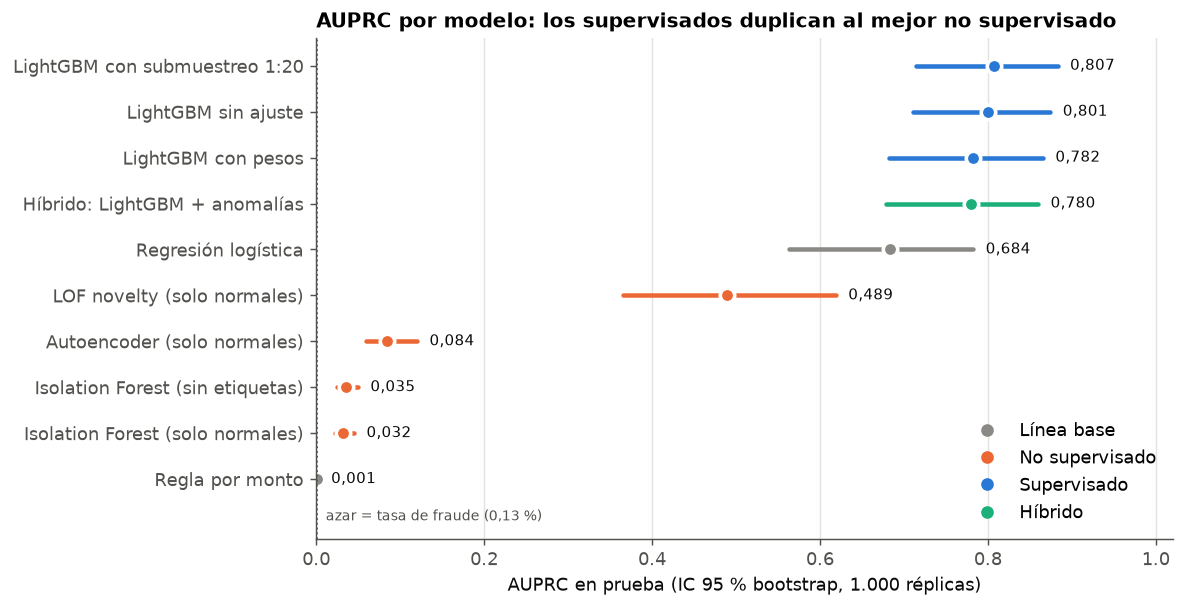

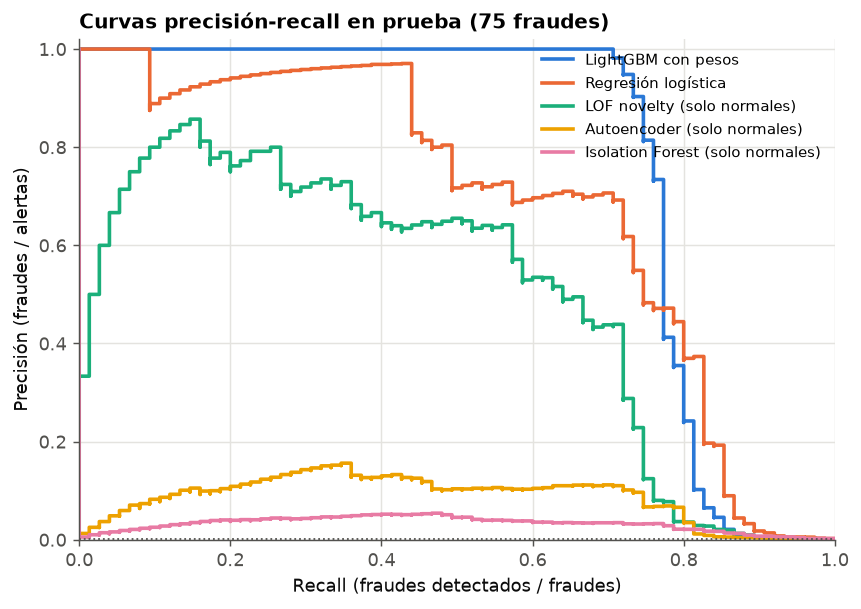

In [4]:
display(Image(filename=str(R / 'figures' / '02_auprc_ic_por_modelo.png')))
display(Image(filename=str(R / 'figures' / '03_curvas_pr_prueba.png')))

### ¿Qué diferencias son significativas? (bootstrap pareado)

In [5]:
d = pd.read_csv(R / 'bootstrap_diferencias.csv')
d[d.metrica == 'auprc'][['comparacion', 'diferencia_media', 'ic_inf', 'ic_sup', 'significativa']]

,comparacion,diferencia_media,ic_inf,ic_sup,significativa
0,hibrido − lgbm_pesos,-0.0025,-0.0165,0.0117,False
1,lgbm_pesos − lof,0.2842,0.1838,0.3868,True
2,lgbm_pesos − logistica,0.0976,0.0343,0.1721,True
3,lgbm_pesos − lgbm_submuestreo,-0.0245,-0.0627,0.0044,False
4,lgbm_pesos − lgbm_sin_ajuste,-0.0186,-0.0541,0.0103,False
5,lgbm_submuestreo − lgbm_sin_ajuste,0.0060,-0.0050,0.0196,False
6,logistica − lof,0.1866,0.1030,0.2794,True
7,lof − autoencoder,0.4106,0.3002,0.5167,True
8,autoencoder − if_normales,0.0538,0.0350,0.0766,True
9,if_normales − if_sin_etiquetas,-0.0036,-0.0063,-0.0014,True


### ¿Por qué rinden tan poco Isolation Forest y el autoencoder?

Detectan lo **raro**, no lo **fraudulento**. Muchas compras legítimas son raras (montos altos, combinaciones poco comunes) y muchos fraudes se parecen a compras normales de pocos euros. Además `V1`–`V28` ya son componentes PCA decorrelacionadas: al autoencoder le queda poca estructura que aprender, y su error se parece a una distancia al centro.

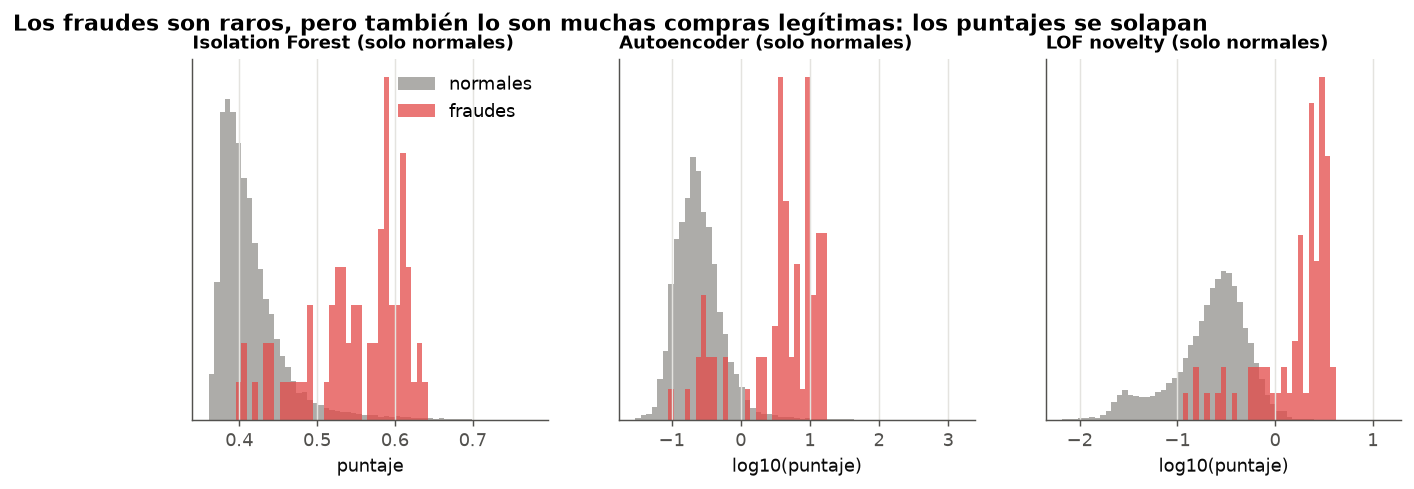

In [6]:
display(Image(filename=str(R / 'figures' / '04_distribucion_puntajes_anomalia.png')))

## Pocas etiquetas: ¿cuántos fraudes etiquetados hacen falta?

In [7]:
g = pd.read_csv(R / 'pocas_etiquetas_resumen.csv')
display(g.pivot(index='n_fraudes', columns='modelo', values='media'))
pe = res['pocas_etiquetas']
print(f"Referencia: {pe['referencia_no_supervisado']} con AUPRC {pe['auprc_referencia']:.3f}")
print('Cruces:', pe['n_fraudes_para_superar'])

modelo,LightGBM con pesos,Regresión logística
n_fraudes,,
5,0.2732,0.5910
10,0.2041,0.5554
20,0.3152,0.5338
35,0.3023,0.5238
50,0.3480,0.5714
100,0.5022,0.5814
200,0.4397,0.6299
360,0.7612,0.6838


Referencia: lof con AUPRC 0.489
Cruces: {'LightGBM con pesos': {'primer_n': 100, 'n_estable': 360}, 'Regresión logística': {'primer_n': 5, 'n_estable': 5}}


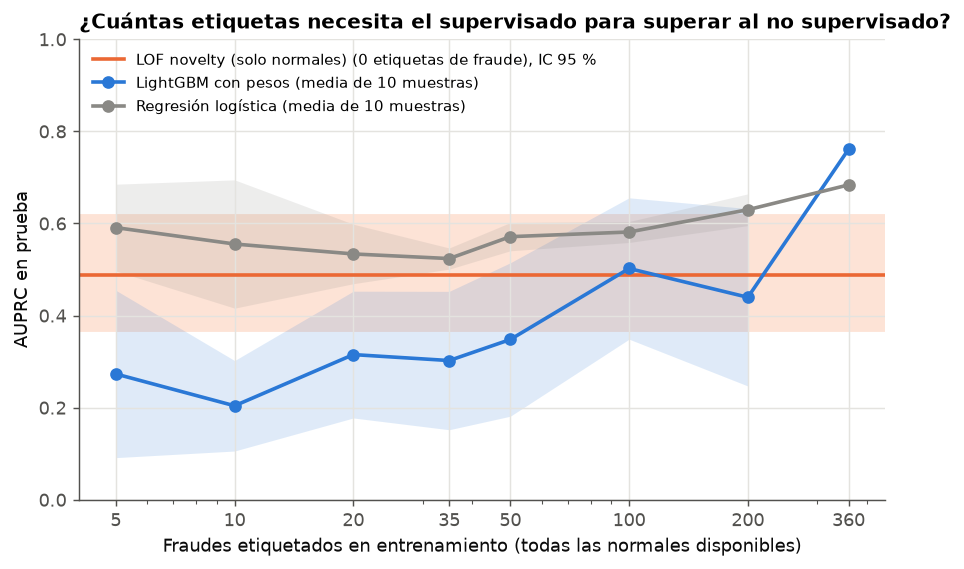

In [8]:
display(Image(filename=str(R / 'figures' / '07_pocas_etiquetas.png')))